## Machine Learning: Modelo Supervisado No 6. Boosting Models

### Andrés Eduardo Rangel Jiménez


- Economista `(Universidad del Valle, Colombia)`

- MSc en Econometria `(Universidad Torcuato Di Tella, Argentina)`

- PhD en Dirección de Empresas `(Universidad de Valencia, España)`

In [6]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import  RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, RocCurveDisplay
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve)
import pickle
import warnings

#### Cargamos base de datos

```
Los registros de viajes de los taxis amarillos y verdes incluyen campos que capturan las fechas y horas de recogida y llegada, los lugares de recogida y llegada, las distancias recorridas, las tarifas detalladas, los tipos de tarifa, los métodos de pago y el número de pasajeros reportado por el conductor.



In [20]:
datos = pd.read_parquet('yellow_tripdata_2024-01.parquet')
datos.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


#### Objetivo. 

Deseamos construir un modelo que prediga si el cliente va a pagar con tarjeta de credito o en efectivo.

### 0. Construyendo la variable dependiente
```
Para modelar la probabilidad de pagar con tarjeta, filtramos  solo 1 y 2 (recomendada)

In [10]:
# Filtrar solo pagos con tarjeta (1) y efectivo (2)
datos = datos[datos["payment_type"].isin([1, 2])].copy()

# Crear variable objetivo binaria
datos["card"] = (datos["payment_type"] == 1).astype(int)

print(datos['card'].value_counts(normalize=True))

card
1    0.840771
0    0.159229
Name: proportion, dtype: float64


### 1. Feature engineering determinístico 
```

La regla que define qué va en el feature engineering determinístico
Una transformación es determinística cuando depende solo de los datos de entrada de una fila, no de estadísticos calculados a partir del target

Crear hour, trip_duration_min, etc., que no dependen del target → sobre datos completos.

In [12]:
# Asegurar datetime parseado (por si acaso)
datos['tpep_pickup_datetime']  = pd.to_datetime(datos['tpep_pickup_datetime'])
datos['tpep_dropoff_datetime'] = pd.to_datetime(datos['tpep_dropoff_datetime'])

# --- Variables temporales básicas (¡estas faltaban!) ---
datos['hour']      = datos['tpep_pickup_datetime'].dt.hour
datos['dayofweek'] = datos['tpep_pickup_datetime'].dt.dayofweek

# --- Duración del viaje en minutos ---
datos['trip_duration_min'] = (
    (datos['tpep_dropoff_datetime'] - datos['tpep_pickup_datetime'])
    .dt.total_seconds() / 60
)

# --- Velocidad promedio en millas/hora (con protección contra división por cero) ---
datos['avg_speed_mph'] = datos['trip_distance'] / (
    datos['trip_duration_min'] / 60
).replace(0, np.nan)

# --- Tarifa por milla ---
datos['fare_per_mile'] = datos['fare_amount'] / datos['trip_distance'].replace(0, np.nan)

# --- Features binarias temporales (ahora sí 'hour' y 'dayofweek' existen) ---
datos['is_weekend']   = datos['dayofweek'].isin([5, 6]).astype(int)
datos['is_rush_hour'] = datos['hour'].isin([7, 8, 9, 17, 18, 19]).astype(int)
datos['is_night']     = datos['hour'].isin([22, 23, 0, 1, 2, 3]).astype(int)

# ---  Dictotomicas aeropuesto ---
datos["airport"] = (datos["Airport_fee"] > 0).astype(int)


# --- Limpieza de valores imposibles ---
datos = datos[
    datos['trip_duration_min'].between(1, 180) &
    datos['avg_speed_mph'].between(1, 80)
].reset_index(drop=True)

# --- Rellenar NaN residuales con mediana ---
for col in ['avg_speed_mph', 'fare_per_mile']:
    datos[col] = datos[col].fillna(datos[col].median())

print(f"Filas después de FE: {len(datos):,}")
print("Nuevas columnas creadas:", [
    'hour', 'dayofweek', 'trip_duration_min', 'avg_speed_mph', 'fare_per_mile',
    'is_weekend', 'is_rush_hour', 'is_night'
])

Filas después de FE: 2,718,664
Nuevas columnas creadas: ['hour', 'dayofweek', 'trip_duration_min', 'avg_speed_mph', 'fare_per_mile', 'is_weekend', 'is_rush_hour', 'is_night']


In [14]:
cols_necesarias = [
    'fare_amount', 'trip_distance', 'hour', 'passenger_count', 'dayofweek',
    'trip_duration_min', 'avg_speed_mph', 'fare_per_mile',
    'is_weekend', 'is_rush_hour', 'is_night',
    'card',  # para el split estratificado
]

faltantes = [c for c in cols_necesarias if c not in datos.columns]
if faltantes:
    print("FALTAN estas columnas:", faltantes)
else:
    print("✓ Todas las columnas existen, puedes continuar al Paso 2")

✓ Todas las columnas existen, puedes continuar al Paso 2


### Paso 2: Definiendo features
```
Los features deterministicos definidos antes de muestrear

Una feature determinística da exactamente el mismo resultado fila por fila sin importar dónde la calcules en el pipeline. Matemáticamente es idéntico hacer:

datos → FE → muestra → split
datos → muestra → FE → split
datos → muestra → split → FE (sobre X_train y X_test por separado)

Sin embargo por razones practicas hay una  razon concreta por la que el lugar correcto es siempre antes de la muestra:

Si quieres estratificar o filtrar usando la feature nueva, tiene que existir.

Si decides que tu muestra debe estratificarse no solo por card sino también por is_airport_trip, o que quieres excluir viajes con trip_duration_min < 1, necesitas la columna creada antes del muestreo.

Los pipelines se leen mejor cuando están organizados por etapas.
El orden canónico en ML es:

1. Carga de datos
2. Limpieza + FE determinístico       ← "preparación de los datos"
3. Muestreo / split                   ← "separar train y test"
4. FE dependiente de y (target enc.)  ← "transformaciones que aprenden de y_train"
5. Escalado (si aplica)               ← ídem
6. Entrenamiento                      ← modelo
7. Evaluación                         ← métricas

In [16]:
features = [
    'fare_amount', 'trip_distance', 'hour', 'passenger_count', 'dayofweek',
    'trip_duration_min', 'avg_speed_mph', 'fare_per_mile',
    'is_weekend', 'is_rush_hour', 'is_night',
    'PULocationID', 'DOLocationID',  
]

#####  Nota: no voy a muestrear pues no voy a hacer GridSearch (dado que no incrementa sustancialmente el desempeño del modelo

### Paso 3:  Muestrea primero 
```
Al muestrear primero reduces el volumen antes de cualquier operación costosa.


In [18]:
#Con un desbalance de 84/16 la versión estratificada es la correcta:
datos_muestra = (
    datos.groupby('card', group_keys=False)
         .sample(frac=0.2, random_state=42)
        .reset_index(drop=True)
)
print(f"Muestra: {len(datos_muestra):,} filas")

Muestra: 543,732 filas


### Paso 4. Split:

In [22]:
X = datos_muestra[features]
y = datos_muestra['card']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [26]:
X_train.shape

(434985, 13)

In [28]:
X_test.shape

(108747, 13)

### Paso 5: Target encoding

In [30]:
# PULocationID — construimos el mapa SOLO con train
pu_map = X_train.join(y_train).groupby("PULocationID")["card"].mean()
X_train["PULocationID_enc"] = X_train["PULocationID"].map(pu_map)
X_test["PULocationID_enc"]  = X_test["PULocationID"].map(pu_map).fillna(pu_map.mean())

# DOLocationID — idem
do_map = X_train.join(y_train).groupby("DOLocationID")["card"].mean()
X_train["DOLocationID_enc"] = X_train["DOLocationID"].map(do_map)
X_test["DOLocationID_enc"]  = X_test["DOLocationID"].map(do_map).fillna(do_map.mean())

# Eliminar columnas originales de ID (ya no se usan como numéricas)
X_train = X_train.drop(columns=["PULocationID", "DOLocationID"])
X_test  = X_test.drop(columns=["PULocationID", "DOLocationID"])

print("Shape train:", X_train.shape, "Shape test:", X_test.shape)
print("Columnas finales:", X_train.columns.tolist())

Shape train: (434985, 13) Shape test: (108747, 13)
Columnas finales: ['fare_amount', 'trip_distance', 'hour', 'passenger_count', 'dayofweek', 'trip_duration_min', 'avg_speed_mph', 'fare_per_mile', 'is_weekend', 'is_rush_hour', 'is_night', 'PULocationID_enc', 'DOLocationID_enc']


#### Modelos Boosting

ADABOOST
              precision    recall  f1-score   support

    Efectivo       0.24      0.29      0.26     17042
     Tarjeta       0.86      0.83      0.85     91705

    accuracy                           0.75    108747
   macro avg       0.55      0.56      0.55    108747
weighted avg       0.77      0.75      0.76    108747

AUC-ROC: 0.5593
GRADIENT BOOSTING
              precision    recall  f1-score   support

    Efectivo       0.23      0.56      0.33     17042
     Tarjeta       0.89      0.66      0.76     91705

    accuracy                           0.64    108747
   macro avg       0.56      0.61      0.54    108747
weighted avg       0.79      0.64      0.69    108747

AUC-ROC: 0.6526
scale_pos_weight correcto: 0.19
[0]	validation_0-auc:0.56339
[50]	validation_0-auc:0.64232
[100]	validation_0-auc:0.64690
[150]	validation_0-auc:0.64974
[200]	validation_0-auc:0.65147
[250]	validation_0-auc:0.65287
[300]	validation_0-auc:0.65399
[350]	validation_0-auc:0.65475
[400]	vali

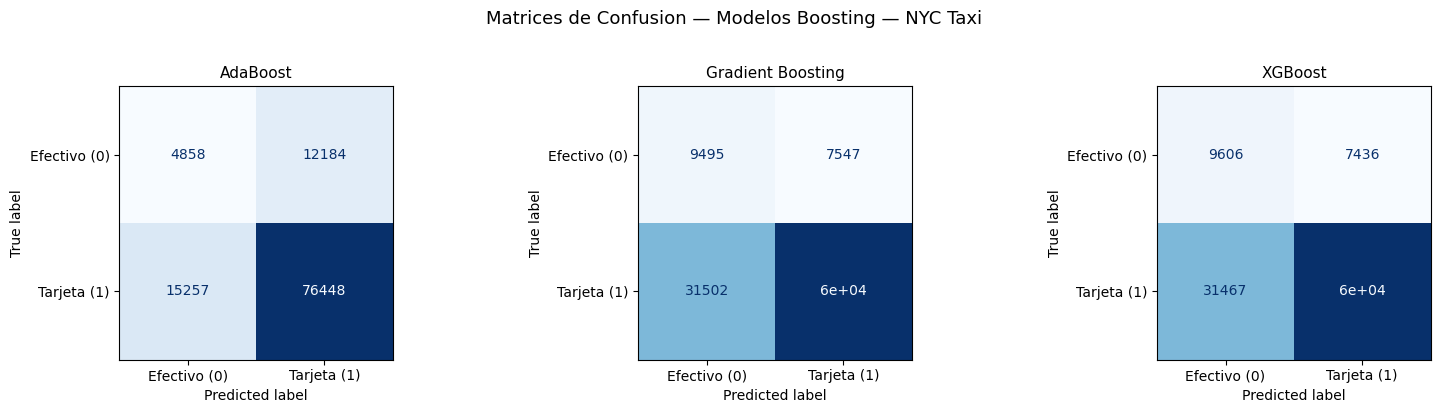

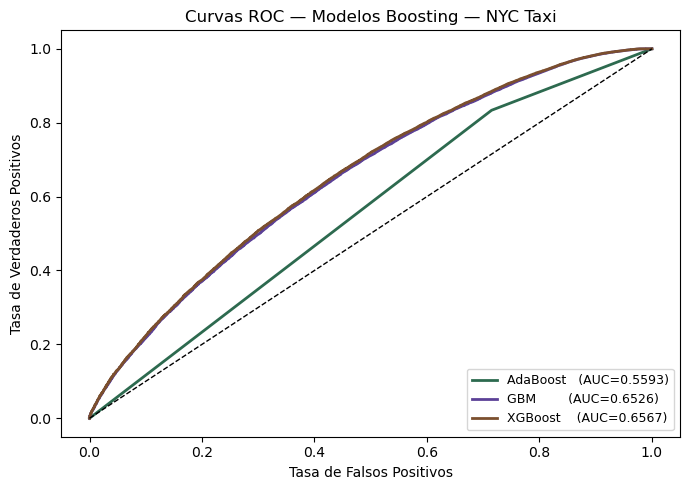

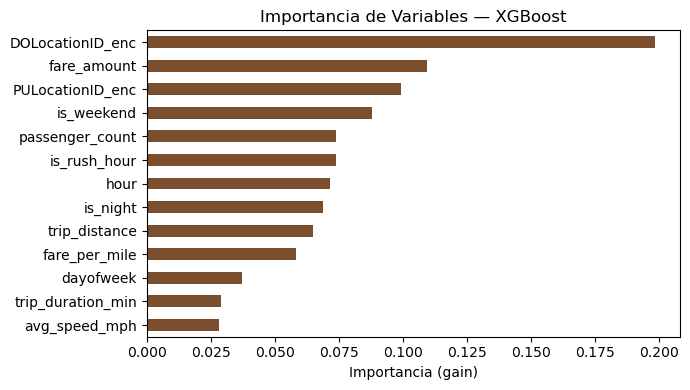

In [32]:
# ═══════════════════════════════════════════════════════════════════
# MODELOS BOOSTING — NYC Taxi 2024: Tarjeta vs Efectivo
# ═══════════════════════════════════════════════════════════════════

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier

# ═══════════════════════════════════════════════════════════════════
# MODELO 1 — AdaBoost
# ═══════════════════════════════════════════════════════════════════
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        class_weight='balanced'  
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)
ada.fit(X_train, y_train)

y_pred_ada  = ada.predict(X_test)
y_proba_ada = ada.predict_proba(X_test)[:, 1]

print("=" * 55)
print("ADABOOST")
print("=" * 55)
print(classification_report(y_test, y_pred_ada,
      target_names=['Efectivo', 'Tarjeta']))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_ada):.4f}")



# ═══════════════════════════════════════════════════════════════════
# MODELO 2 — Gradient Boosting
# ═══════════════════════════════════════════════════════════════════
# Calcular pesos por observacion a partir de y_train

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

gbm = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    min_samples_leaf=50,
    random_state=42
    # sin class_weight aqui
)

# El balanceo va en el fit, no en el constructor
gbm.fit(X_train, y_train, sample_weight=sample_weights)

y_pred_gbm  = gbm.predict(X_test)
y_proba_gbm = gbm.predict_proba(X_test)[:, 1]

print("=" * 55)
print("GRADIENT BOOSTING")
print("=" * 55)
print(classification_report(y_test, y_pred_gbm,
      target_names=['Efectivo', 'Tarjeta']))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_gbm):.4f}")


# ═══════════════════════════════════════════════════════════════════
# MODELO 3 — XGBoost
# ═══════════════════════════════════════════════════════════════════
import xgboost as xgb

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
print(f"scale_pos_weight correcto: {neg/pos:.2f}")

model_xgb = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=neg/pos,    # solo este, quitar el scale_pos_weight=5
    early_stopping_rounds=20,
    eval_metric='auc',
    random_state=42,
    verbosity=0
)

model_xgb.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=50
)

y_pred_xgb  = model_xgb.predict(X_test)
y_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]

print("=" * 55)
print("XGBOOST")
print("=" * 55)
print(f"Arboles usados (early stopping): {model_xgb.best_iteration}")
print(classification_report(y_test, y_pred_xgb,
      target_names=['Efectivo', 'Tarjeta']))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba_xgb):.4f}")


# ═══════════════════════════════════════════════════════════════════
# COMPARACION FINAL — tabla resumen
# ═══════════════════════════════════════════════════════════════════
print("\n" + "=" * 55)
print(f"{'Modelo':<22} {'AUC-ROC':>10} {'Accuracy':>10}")
print("=" * 55)
for nombre, y_pred, y_proba in [
    ("AdaBoost",          y_pred_ada, y_proba_ada),
    ("Gradient Boosting", y_pred_gbm, y_proba_gbm),
    ("XGBoost",           y_pred_xgb, y_proba_xgb),
]:
    auc = roc_auc_score(y_test, y_proba)
    acc = (y_pred == y_test).mean()
    print(f"{nombre:<22} {auc:>10.4f} {acc:>10.4f}")
print("=" * 55)


# ═══════════════════════════════════════════════════════════════════
# MATRICES DE CONFUSION — los 3 modelos
# ═══════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, y_pred, titulo in zip(
    axes,
    [y_pred_ada, y_pred_gbm, y_pred_xgb],
    ["AdaBoost", "Gradient Boosting", "XGBoost"]
):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Efectivo (0)", "Tarjeta (1)"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(titulo, fontsize=11)

plt.suptitle("Matrices de Confusion — Modelos Boosting — NYC Taxi",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════════
# CURVAS ROC COMPARATIVAS
# ═══════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(7, 5))

for y_proba, label, color in [
    (y_proba_ada, f"AdaBoost   (AUC={roc_auc_score(y_test, y_proba_ada):.4f})", "#2d6a4f"),
    (y_proba_gbm, f"GBM        (AUC={roc_auc_score(y_test, y_proba_gbm):.4f})", "#5c4197"),
    (y_proba_xgb, f"XGBoost    (AUC={roc_auc_score(y_test, y_proba_xgb):.4f})", "#7b4f2e"),
]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax.plot(fpr, tpr, label=label, lw=2, color=color)

ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel("Tasa de Falsos Positivos")
ax.set_ylabel("Tasa de Verdaderos Positivos")
ax.set_title("Curvas ROC — Modelos Boosting — NYC Taxi")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()


# ═══════════════════════════════════════════════════════════════════
# IMPORTANCIA DE VARIABLES — XGBoost
# ═══════════════════════════════════════════════════════════════════
importancias_xgb = pd.Series(
    model_xgb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
importancias_xgb.plot(kind="barh", ax=ax, color="#7b4f2e")
ax.set_title("Importancia de Variables — XGBoost")
ax.set_xlabel("Importancia (gain)")
plt.tight_layout()
plt.show()

#### Realizando GridSearch sobre el modelo XGBoost

In [36]:
# ═══════════════════════════════════════════════════════════════════
# GRID SEARCH — XGBoost (RandomizedSearchCV)
# ═══════════════════════════════════════════════════════════════════
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

neg = (y_train == 0).sum()
pos = (y_train == 1).sum()

parametros_xgb = {
    'n_estimators'      : [200, 300, 500],
    'learning_rate'     : [0.01, 0.05, 0.1],
    'max_depth'         : [3, 4, 6],
    'subsample'         : [0.7, 0.8, 1.0],
    'colsample_bytree'  : [0.6, 0.8, 1.0],
    'gamma'             : [0, 0.1, 0.5],
    'reg_alpha'         : [0, 0.1, 0.5],
    'reg_lambda'        : [0.5, 1.0, 2.0],
}

xgb_base = xgb.XGBClassifier(
    scale_pos_weight=neg/pos,
    eval_metric='auc',
    random_state=42,
    verbosity=0
)

random_search_xgb = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=parametros_xgb,
    n_iter=20,              # 20 combinaciones aleatorias
    scoring='roc_auc',
    cv=3,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search_xgb.fit(X_train, y_train)

print("Mejores hiperparametros:", random_search_xgb.best_params_)
print(f"Mejor AUC-ROC (CV):     {random_search_xgb.best_score_:.4f}")

# ── Evaluar modelo final ──────────────────────────────────────────
xgb_final   = random_search_xgb.best_estimator_
y_pred_xgb  = xgb_final.predict(X_test)
y_proba_xgb = xgb_final.predict_proba(X_test)[:, 1]

print("\n" + "=" * 55)
print("XGBOOST — Modelo final (RandomizedSearchCV)")
print("=" * 55)
print(classification_report(y_test, y_pred_xgb,
      target_names=['Efectivo', 'Tarjeta']))
print(f"AUC-ROC (test): {roc_auc_score(y_test, y_proba_xgb):.4f}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Mejores hiperparametros: {'subsample': 0.8, 'reg_lambda': 2.0, 'reg_alpha': 0, 'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.6}
Mejor AUC-ROC (CV):     0.6587

XGBOOST — Modelo final (RandomizedSearchCV)
              precision    recall  f1-score   support

    Efectivo       0.24      0.56      0.33     17042
     Tarjeta       0.89      0.66      0.76     91705

    accuracy                           0.65    108747
   macro avg       0.56      0.61      0.55    108747
weighted avg       0.79      0.65      0.69    108747

AUC-ROC (test): 0.6593


```

Por que RandomizedSearch y no GridSearch?

  GridSearch con 8 parametros x 3 valores cada uno:
  3^8 = 6,561 combinaciones x 3 folds = 19,683 entrenamientos
  → dias de computo

  RandomizedSearch con n_iter=20:
  20 combinaciones x 3 folds = 60 entrenamientos
  → minutos
  → con buena probabilidad encuentra una combinacion
    cercana al optimo

#### Diferencia entre GridSearch y RandomizedSearch (ver material html)

#### Sobreajuste o subajuste ?

In [38]:
# ═══════════════════════════════════════════════════════════════════
# DIAGNOSTICO DE OVERFITTING / UNDERFITTING
# ═══════════════════════════════════════════════════════════════════

from sklearn.metrics import roc_auc_score

modelos = {
    "AdaBoost"         : (ada,       None),
    "Gradient Boosting": (gbm,       sample_weights),
    "XGBoost"          : (model_xgb, None),
}

print("=" * 65)
print(f"{'Modelo':<22} {'AUC Train':>10} {'AUC Test':>10} {'Diferencia':>12} {'Diagnostico':>12}")
print("=" * 65)

for nombre, (modelo, sw) in modelos.items():

    # prediccion sobre train
    y_proba_train = modelo.predict_proba(X_train)[:, 1]
    auc_train = roc_auc_score(y_train, y_proba_train)

    # prediccion sobre test (ya las tienes calculadas)
    if nombre == "AdaBoost":
        auc_test = roc_auc_score(y_test, y_proba_ada)
    elif nombre == "Gradient Boosting":
        auc_test = roc_auc_score(y_test, y_proba_gbm)
    else:
        auc_test = roc_auc_score(y_test, y_proba_xgb)

    diff = auc_train - auc_test

    if diff > 0.05:
        diag = "OVERFIT"
    elif auc_test < 0.65:
        diag = "UNDERFIT"
    else:
        diag = "OK"

    print(f"{nombre:<22} {auc_train:>10.4f} {auc_test:>10.4f} {diff:>12.4f} {diag:>12}")

print("=" * 65)

Modelo                  AUC Train   AUC Test   Diferencia  Diagnostico
AdaBoost                   0.5626     0.5593       0.0032     UNDERFIT
Gradient Boosting          0.6613     0.6526       0.0087           OK
XGBoost                    0.6693     0.6593       0.0100           OK


#### Una nota sobre la Heuristica en Machine Learning

```
Una heurística es una regla práctica que funciona en la mayoría de los casos pero que no está derivada matemáticamente ni demostrada como óptima. Es básicamente un "atajo razonable" basado en experiencia o intuición, no en una demostración formal.
La palabra viene del griego heuriskein — "encontrar, descubrir". Es el mismo origen que el famoso "¡Eureka!" de Arquímedes.

Ejemplos de heurísticas en machine learning:

"Usa learning_rate = 0.1 como punto de partida" — funciona empíricamente bien, pero nadie demostró que sea óptimo. Es una regla que la comunidad encontró por prueba y error.

"Pon n_estimators entre 100 y 500" — heurística práctica, no resultado matemático.

"Si tienes muchas features, prueba max_depth = sqrt(n_features)" — Random Forest usa esto por convención, no por demostración.

El contraste con la fórmula de alpha:
Cuando dije "no es arbitraria ni heurística" quería resaltar que α = 0.5·ln((1-err)/err) no es una regla práctica que alguien probó y vio que funcionaba. Es la solución exacta a un problema matemático bien definido (minimizar la pérdida exponencial). Si cambiaras ese 0.5 por 0.4 o 0.6, el algoritmo sería peor — y se puede demostrar matemáticamente por qué.
